# Running a reconstruction asynchronously

It is often needed to monitor the reconstruction process while it takes place. However, the `spring.MPR.run()` method blocks the interpreter during the process, making it impossible to inspect the reconstruction while it is ongoing.

The `spring.MPR` class provides a further method which allows to run a reconstruction *asynchronously*, i.e without blocking the interpreter. 

To perform the process in an asynchronous way, the `Settings` and the `Pattern` are prepared in the usual way:

In [1]:
import numpy as np
data = np.load('data/example_B_1.npz')

from spring import Pattern, Settings
patt = Pattern(pattern=data['pattern'], 
               mask=data['mask'], 
               center=data['center'], 
               pid=data['pid'],
               cropsize=1024,
               size=256,
               satvalue=3e4)

sett = Settings()
sett.set('IA','it', 50).set('init','supportsize',90).set('global','gpus',1);

The MPR process can be now started but, instead of using the `MPR.run()` method, the `MPR.runasync()` function is called:

In [2]:
from spring import MPR

# Blocking call
# rec = MPR(pattern=patt, settings=sett).run()

# Async call
MPR(pattern=patt, settings=sett).runasync()

The function immediately returns, and the reconstruction is performed in the background by a child process. 

## Monitoring the reconstruction process

As the reconstruction is executed in the background, the `MPR.runasync()` method isn't printing any output and the function immediately returns.
For the monitoring and control of the reconstruction it is then necessary to use a helper tool, `spring.hypervisor`. The object can be imported as it follows:


In [3]:
from spring import hypervisor as hv

The `info()` method allows for a quick inspection of the current status:

In [5]:
hv.info()

Running: 190-1769647347
Empty queue.


The `livelog` method reports the live status of the process. It is automatically updated in the background by a child process, leaving the console free to accept further commands. The command is a *switch*, meaning that it starts a live logging if the livelogging is not running, or it switches it off if it is already running

In [6]:
hv.livelog()



Selected GPUs:
  - NVIDIA GeForce RTX 3090 (Id: 0, load: 0%)
Initializing solver... Done.
Initializing algorithms... Done.
Initializing population... Done.
... Running main loop ...
- - - - - - - - - - - - - - - - - - - - -
RUNNING 190-1769647347 [####------] 40%

The `liveplot` method shows the current result of the ongoing reconstruction. It is automatically updated in the background by a child process, leaving the console free to accept further commands. Also this command is a switch, meaning that it starts the live plotting if not already running, otherwise it stops it.

Starting live plotting


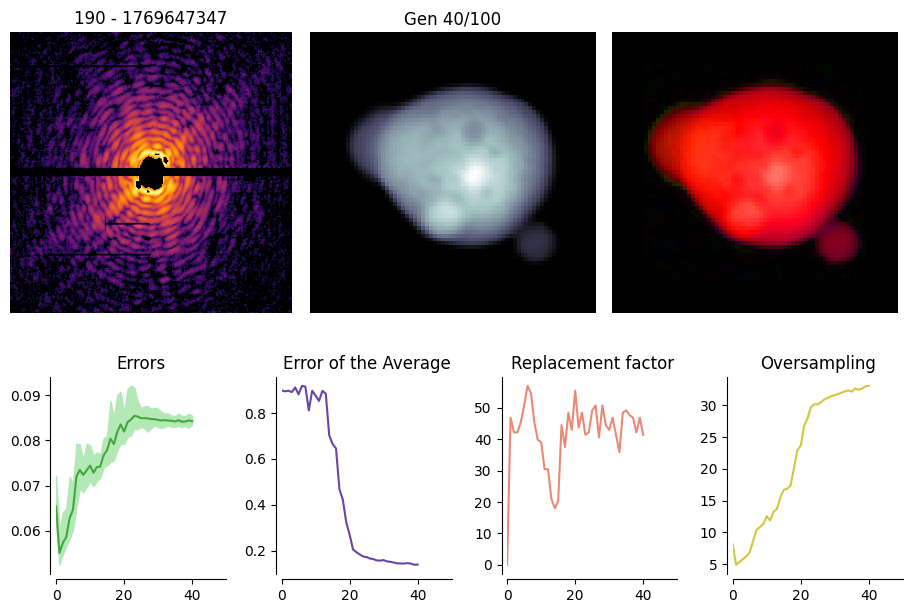

In [9]:
hv.liveplot()

The reconstruction at the current step can be directly accessed as a `spring.Result` object by calling `hv.get()`. In the following example the `plot()` method of the `Result` is called, to plot the reconstruction.

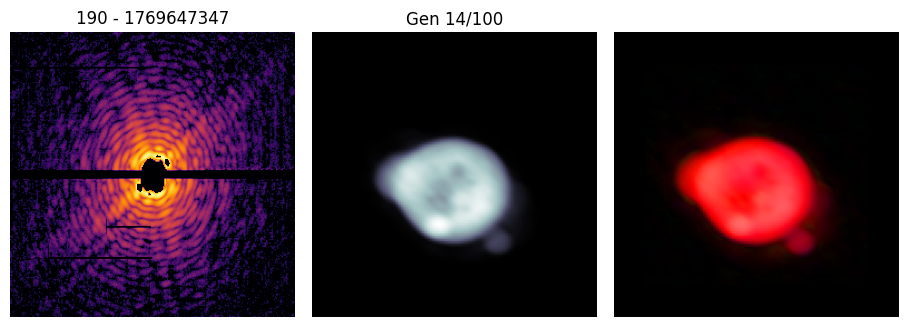

In [7]:
hv.get().plot()

The live plotting can be interrupted by calling again the `liveplot()` method

In [8]:
hv.liveplot()

Stopping live plotting... Done


The current reconstruction process can be interrupted in the following way:

In [51]:
hv.stop()

Terminating running MPR process... Done


> **Warning**
> It is important to use the `stop()` method of the hypervisor to stop the asynchronous reconstruction. If the kernel is manually stopped the behavior is undefined and the kernel has probably to be restarted


If a new `MPR.runasync()` call is made, the new reconstruction process is [queued for execution](/workflow) after the currently running one. 